<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DEMO_PRAK_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama:** Wawa Elent Irawanti

**NIM:** 244107020192

**Kelas:** TI-3H

## Praktikum 1

### Klasifikasi SVM dengan Data Dummy Linier

Langkah 1 - Import Library

In [1]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

Langkah 2 - Membuat Data Dummy

Pada praktikum ini, model yang digunakan adalah sebuah model yang sederhana berupa generative model untuk menentukan label pada poin baru. Kasus pada data dummy ini memperlihatkan dua kelas yang telah terpisah.

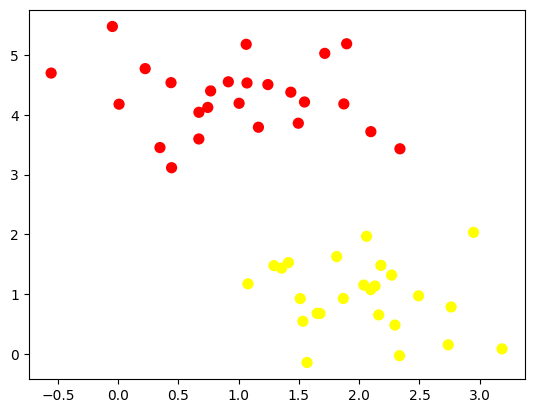

In [2]:
	from sklearn.datasets import make_blobs
	X, y = make_blobs(n_samples=50, centers=2,
	                  random_state=0, cluster_std=0.60)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Buat Ilustrasi Garis Pemisah

Untuk membuat sebuah model klasifikasi, garis pemisah data dari dua buah himpunan yang terbentuk diperlukan. Namun, kondisi ini masih menyisakan kasus dimana garis pemisah yang dibutuhkan lebih dari satu garis.

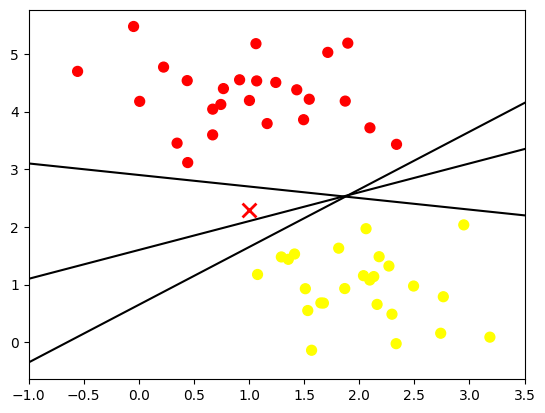

In [3]:
# Langkah 3 - Buat Ilustrasi Garis Pemisah

xfit = np.linspace(-1, 3.5)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')

# Titik x
plt.scatter(1.0, 2.3, marker='x', color='red',
            s=100, linewidths=2)

plt.xlim(-1, 3.5)
plt.show()



Banyaknya garis pemisah menunjukkan bahwa muncul beberapa kemungkinan suatu data baru masuk dalam kategori tertentu. Sebuah data baru 'x' dimunculkan pada posisi yang berbeda dengan data pada dua himpunan lain sehingga data baru ini tidak masuk ke dalam kategori dua himpunan sebelumnya.

Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

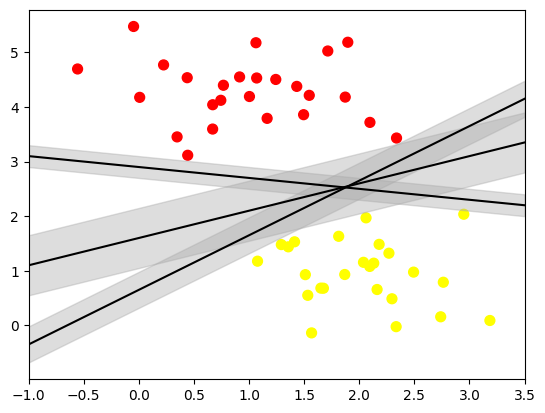

In [4]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

Margin yang digunakan pada SVM berfungsi untuk menunjukkan model yang paling optimal. Kriteria optimal ini diperoleh dari penentuan garis mana yang mampu memaksimalkan margin yang ada.

Langkah 5 - Fitting Model

In [5]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

Selanjutnya buat fungsi untuk membantu visualisasi hasil fit model.

In [6]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Lakukan plotting dengan fungsi yang telah dibuat.

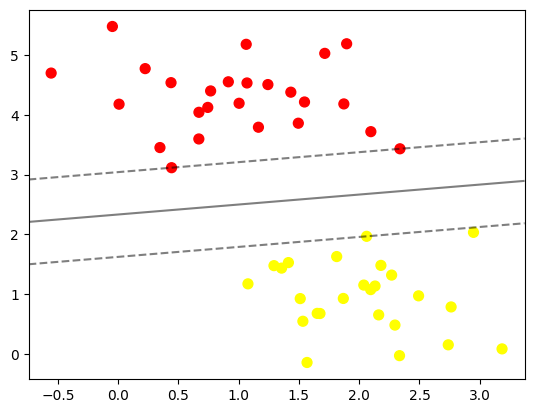

In [7]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

Beberapa titik data yang menyentuh (masuk ke area) garis disebut sebagai support vector. Untuk mengetahui data yang masuk ke dalam support vector dapat dilakukan dengan memanggil support_vectors_

In [8]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Hasil fitting merupakan kunci keberhasilan suatu classifier (yang hanya dilihat dari posisi dari support vector). Data-data lain yang berada jauh dari margin dan tetap berada di area yang tepat tidak memiliki kemampuan untuk memodifikasi fitting (karena bukan support vector). Data-data tersebut tidak berkontribusi terhadap loss function yang digunakan untuk fitting model. Untuk lebih memahami hal ini, 60 dan 120 data awal digunakan sebagai contoh dalam bentuk perbandingan.

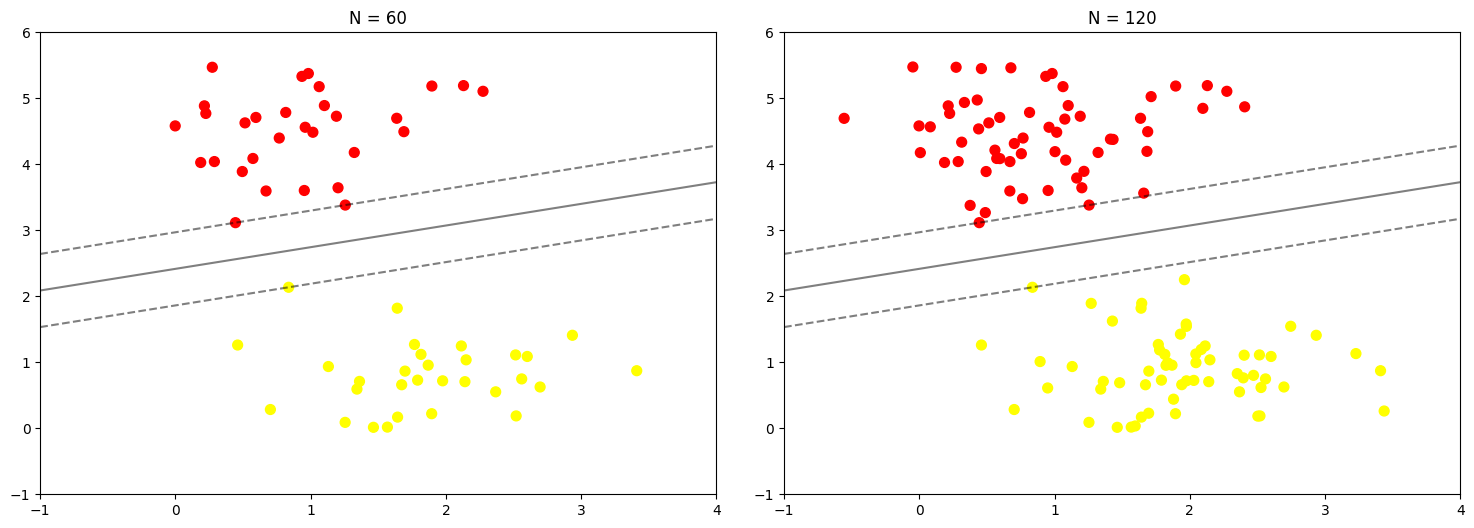

In [9]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

Berdasarkan hasil di atas, perubahan jumlah data tidak mempengaruhi model yang digunakan. Ilustrasi lebih jelas dapat dilihat pada diagram di bawah ini

In [10]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 51.8 MB/s eta 0:00:00


In [11]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

## Praktikum 2


### Klasifikasi SVM dengan Data Dummy Non-Linier

Langkah 1 - Ilustrasi Data Non-Linier

Data yang terpisah secara tidak linier menjadi masalah pada model SVM. Oleh karena itu, kernel menjadi sebuah kebutuhan bagi SVM untuk melakukan fitting pada hubungan non-linier dengan sebuah classifier linier.

Langkah 1a - Import Library

In [12]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting

In [13]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 1c - Buat Data Dummy Non-Linier

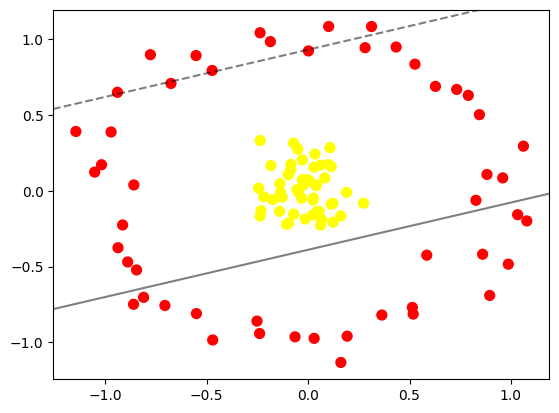

In [14]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

Karena proyeksi radial tidak cukup menggunakan model 2D, maka plot visualisasi diubah menjadi model 3D.

In [15]:
# Menghitung nilai proyeksi radial
r = np.exp(-(X**2).sum(axis=1))

print(r)


[0.84717161 0.36065353 0.33208465 0.37888879 0.98609218 0.42520193
 0.99703026 0.96067201 0.41944722 0.97970952 0.93123552 0.97971716
 0.96294262 0.96602431 0.96682414 0.94384409 0.99370957 0.38066686
 0.9968374  0.92477104 0.98160877 0.47683337 0.37381991 0.34363786
 0.99582458 0.29869481 0.41147467 0.36350531 0.95170168 0.94166655
 0.39398881 0.34279625 0.97934911 0.37225435 0.30055915 0.9465146
 0.99666786 0.97850029 0.33450835 0.30548218 0.27042828 0.40035456
 0.99784987 0.33673736 0.94035504 0.96283575 0.96015559 0.23100011
 0.31860293 0.99460212 0.29698952 0.94163852 0.97506748 0.9820888
 0.96449584 0.97189167 0.94661813 0.99683227 0.97473749 0.97853679
 0.38306306 0.42658694 0.395258   0.45407875 0.99732403 0.38772586
 0.96816688 0.99758126 0.39481338 0.27214916 0.278708   0.24365155
 0.99543361 0.96217571 0.50231125 0.3159554  0.90060582 0.36636981
 0.38314555 0.94819643 0.3355747  0.95836508 0.28012772 0.92217066
 0.32513782 0.94189015 0.30444084 0.91985684 0.36045163 0.384483

In [16]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.23617757,  0.33177122],
       [-0.93763762, -0.37506429],
       [-0.55289123,  0.89256745],
       [ 0.28092395,  0.9442427 ],
       [ 0.08230087,  0.08504121],
       [-0.47358055,  0.79430004],
       [ 0.02585651, -0.04801668],
       [ 0.09992586,  0.17360026],
       [ 0.6277945 ,  0.6889787 ],
       [ 0.11312136, -0.08776515],
       [-0.23244764, -0.13119129],
       [ 0.0457895 , -0.13562699],
       [-0.08502854,  0.17473294],
       [-0.01542735, -0.18527892],
       [-0.17433335, -0.05784933],
       [ 0.12255443, -0.20682045],
       [-0.02948121,  0.07376421],
       [ 0.84451108,  0.50262481],
       [ 0.0411461 ,  0.03840069],
       [-0.05088412,  0.27499073],
       [-0.13578419, -0.0111852 ],
       [-0.85969334,  0.03892996],
       [ 0.73261942,  0.66876746],
       [-1.019079  ,  0.17217697],
       [ 0.02407039, -0.06003982],
       [ 0.9871258 , -0.48364822],
       [-0.91505957, -0.22510843],
       [-0.88990391, -0.46907613],
       [-0.2190358 , -0.03907642],
       [-0.2445267 ,  0.01762784],
       [-0.06466711, -0.9629387 ],
       [-0.70639413, -0.75605977],
       [-0.09816911,  0.10597138],
       [-0.84615633, -0.52172539],
       [ 1.0783051 , -0.19841575],
       [-0.09654521, -0.21365371],
       [-0.03174041, -0.04827271],
       [ 0.12212608, -0.08257978],
       [-0.9717712 ,  0.38827074],
       [ 0.10115369,  1.08426554],
       [ 0.16137526, -1.13212472],
       [ 0.86053277, -0.4181962 ],
       [-0.02187653,  0.04091292],
       [ 0.43392257,  0.94876931],
       [-0.18363934,  0.16665645],
       [-0.14074632, -0.13439835],
       [ 0.06745019, -0.19002738],
       [-1.14540723,  0.3916368 ],
       [-0.23721427,  1.04285142],
       [-0.00326367,  0.07349731],
       [ 1.06163807,  0.29492888],
       [ 0.0336676 ,  0.24289979],
       [ 0.02852039,  0.15631758],
       [-0.12788919, -0.04144764],
       [ 0.18988336, -0.00969924],
       [-0.07152692, -0.1529537 ],
       [ 0.06091545, -0.22616104],
       [-0.05585829,  0.00725324],
       [ 0.02331058, -0.15825202],
       [-0.13955139,  0.04714129],
       [-0.67670414,  0.70825642],
       [ 0.00149112,  0.92300425],
       [ 0.95964385,  0.08544149],
       [ 0.88191529,  0.10821302],
       [ 0.03908811,  0.03393643],
       [ 0.02953521, -0.9729257 ],
       [ 0.06013995,  0.16951104],
       [-0.04872823, -0.00687226],
       [ 0.51814381, -0.81293855],
       [-0.86110928, -0.74826183],
       [ 0.89532279, -0.68991865],
       [-0.77797372,  0.89820546],
       [ 0.00656169,  0.06733344],
       [ 0.11358901,  0.16017407],
       [ 0.82743788, -0.06230473],
       [-0.81162062, -0.70244301],
       [-0.07184356,  0.31547759],
       [-0.18635418,  0.98457309],
       [-0.55111114, -0.80970171],
       [ 0.16097337, -0.16517011],
       [ 1.03308665, -0.15697986],
       [-0.02859418,  0.20422748],
       [ 0.31269152,  1.0838513 ],
       [ 0.27273478, -0.08149055],
       [-1.05271838,  0.12365335],
       [-0.10590105, -0.22057107],
       [-0.47074148, -0.98370775],
       [-0.2366308 , -0.16596113],
       [ 0.78957393,  0.63005596],
       [ 0.19230693, -0.9585777 ],
       [-0.94051338,  0.64988407],
       [ 0.51401911, -0.76910509],
       [ 0.10805478,  0.28514802],
       [ 0.36339012, -0.81912914],
       [ 0.58491403, -0.42425843],
       [-0.25234872, -0.85906122],
       [-0.08623759,  0.13951066],
       [ 0.05424441, -0.13641321],
       [ 0.52674921,  0.83562563],
       [-0.23941234, -0.94093099]]), y=array([1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0]))>

Langkah 2 - Fitting Model

Walaupun data dapat ditampilkan secara terpisah. Proyeksi titik data sejumlah N ke dalan suatu dimensi N menyebabkan beban komputasi juga bertambah. Untuk mengatasi hal ini, kernel radial basis function (RBF) pada Scikit-Learn digunakan.

In [17]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

Plot hasil decision boundaries dari kernel RBF

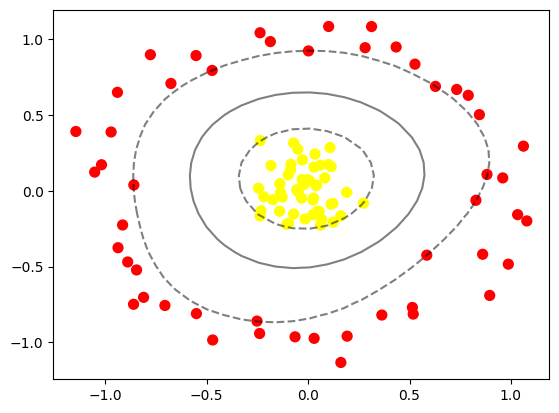

In [18]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')

## Praktikum 3

### SVM Data Overlapping

Langkah 1 - Import Library dan Buat Fungsi Plotting

In [19]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [20]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 2 - Buat Data Dummy

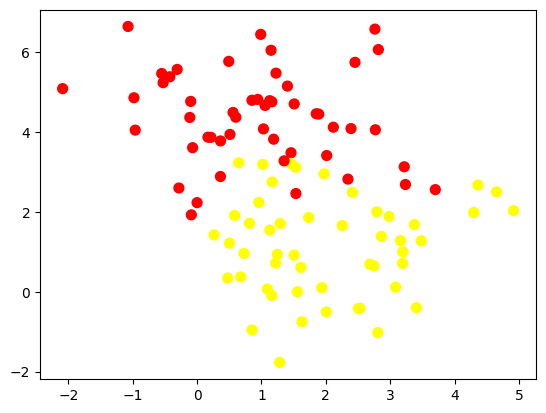

In [21]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Analisis Dampak Tunning

Untuk mengatasi hal ini, teknik penghalusan margin pada SVM dapat diterapkan. Teknik ini berfungsi untuk memasukkan beberapa titik data ke dalam margin supaya menghasilkan fitting yang lebih baik. Penebalan margin dari hasil teknik penghalusan dikelola oleh sebuah parameter tuning (dikenal sebagai C). Contoh dibawah menunjukkan perubahan pada C berdampak pada hasil fitting final.

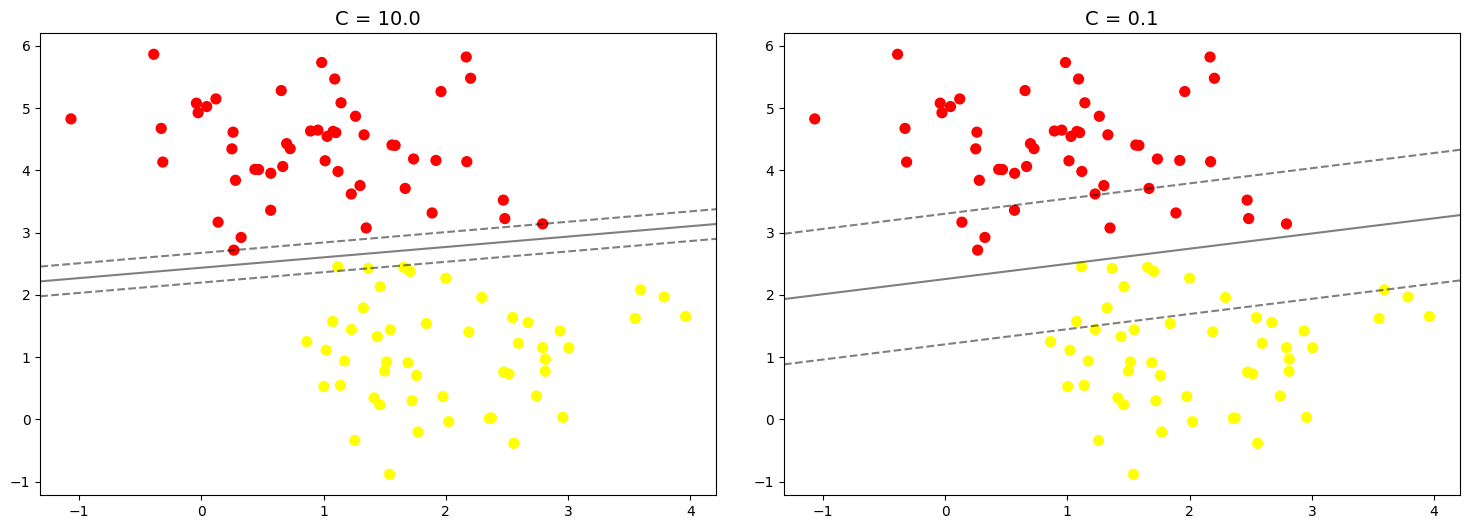

In [22]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)

## Praktikum 4

### Klasifikasi Citra Wajah

Langkah 0 - Unduh Dataset

In [23]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Langkah 1 - Inspeksi Citra Wajah

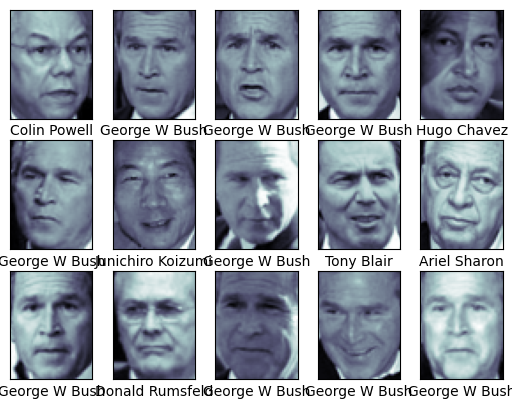

In [24]:
	# contoh wajah yang digunakan
	from matplotlib import pyplot as plt

	fig, ax = plt.subplots(3, 5)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(faces.images[i], cmap='bone')
	    axi.set(xticks=[], yticks=[],
	            xlabel=faces.target_names[faces.target[i]])

Langkah 2 - Pra Pengolahan Data

In [25]:
	from sklearn.svm import SVC
	from sklearn.decomposition import PCA as RandomizedPCA
	from sklearn.pipeline import make_pipeline

	pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
	svc = SVC(kernel='rbf', class_weight='balanced')

	# Pipeline digunakan untuk melakukan proses secara bertahap dalam
	# 1 eksekusi fungsi secara langsung
	model = make_pipeline(pca, svc)

Langkah 3 - Split Data

In [26]:
	# pemisahan data training dan data testing

	from sklearn.model_selection import train_test_split
	Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

Langkah 4 - Pembuatan Model + Tunning

In [27]:
	from sklearn.model_selection import GridSearchCV
	param_grid = {'svc__C': [1, 5, 10, 50],
	              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
	grid = GridSearchCV(model, param_grid)

	%time grid.fit(Xtrain, ytrain)
	print(grid.best_params_)
	print(grid.best_score_)

CPU times: user 2min 3s, sys: 143 ms, total: 2min 3s
Wall time: 1min 17s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Sehingga didapatkan informasi bahwa, hyperparameter terbaik dari model SVM yang kita buat adalah dengan, C=5 dan Gamma=0.001 dengan tingkat akurasi 82.88%.

Gunakan model terbaik tersebut untuk proses prediksi.

In [28]:
	model = grid.best_estimator_
	yfit = model.predict(Xtest)

Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

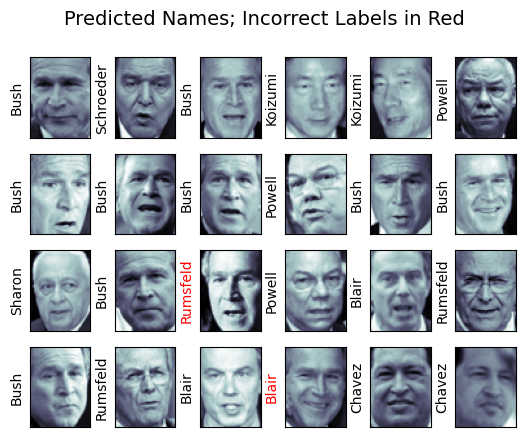

In [29]:
	# hasil label pada data testing

	fig, ax = plt.subplots(4, 6)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
	    axi.set(xticks=[], yticks=[])
	    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
	                   color='black' if yfit[i] == ytest[i] else 'red')
	fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

Contoh di atas hanya menunjukkan satu data dengan label salah. Selanjutnya, kita akan mengukur performa model dengan classification report dan confusion matrix.

Langkah 6 - Cek Performansi

In [30]:
	from sklearn.metrics import classification_report
	print(classification_report(ytest, yfit,
	                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Dari tabel tersebut, kita mendapatkan informasi terkait dengan akurasi keseluruhan, presisi, recall, dan f1-score untuk setiap label.

Selanjutnya, kita dapat menggunakan confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak.

Text(113.92222222222219, 0.5, 'predicted label')

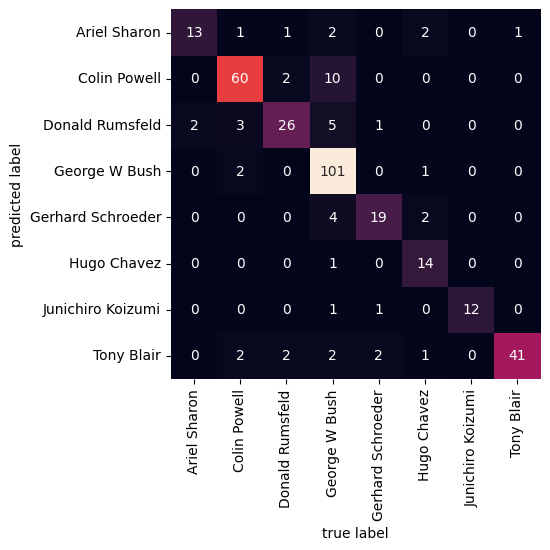

In [31]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')

## Praktikum 5

### Klasifikasi Citra Siang dan Malang

Langkah 0 - Import Library

In [32]:
	# Import Required Libraries
	from pathlib import Path
	import matplotlib.image as mpimg
	import matplotlib.pyplot as plt
	import cv2
	import random
	import numpy as np
	import pandas as pd

Lakukan ekstraksi data gambar, kemudian definisikan lokasi gambar. Pada contoh ini, folder gambar berlokasi sama dengan lokasi file python.

In [33]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

In [37]:

import zipfile
import os
import glob

# Mencari file ZIP di folder Colab
zip_files = glob.glob("/content/*.zip")

print("File ZIP ditemukan:", zip_files)


File ZIP ditemukan: ['/content/images.zip']


In [38]:

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset berhasil diekstrak!")


Dataset berhasil diekstrak!


Langkah 1 - Load Data dan Visualisasikan

In [39]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

Load gambar training

In [40]:
	# Load training data
	train_img = load_dataset(train_dir)

Lakukan pengecekan pada salah satu data pada list. List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar.

In [41]:
	# Check the first data
	# It should be a tuple consist of arrays of image and image labels
	train_img[0]

(array([[[ 81, 103, 124],
         [ 80, 102, 123],
         [ 78, 100, 121],
         ...,
         [ 87, 105, 119],
         [ 83,  96, 112],
         [116, 129, 145]],
 
        [[ 80, 102, 123],
         [ 80, 102, 123],
         [ 78, 100, 121],
         ...,
         [ 87, 105, 119],
         [ 83,  96, 112],
         [116, 129, 145]],
 
        [[ 80, 102, 123],
         [ 79, 101, 122],
         [ 79, 101, 122],
         ...,
         [ 87, 105, 119],
         [ 83,  96, 112],
         [116, 129, 145]],
 
        ...,
 
        [[171, 156, 117],
         [170, 155, 116],
         [169, 154, 115],
         ...,
         [ 73,  77,  42],
         [ 74,  80,  44],
         [ 72,  78,  40]],
 
        [[172, 157, 118],
         [171, 156, 117],
         [170, 155, 116],
         ...,
         [ 76,  80,  45],
         [ 78,  84,  48],
         [ 77,  83,  45]],
 
        [[204, 189, 150],
         [203, 188, 149],
         [201, 186, 147],
         ...,
         [ 89,  93,  58],
  

Cek ukuran gambar secara acak

In [42]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_img))

	# Check img size
	print(f'Image {pick_random}')
	print(train_img[pick_random][0].shape)

Image 235
(372, 640, 3)


Tampilkan gambar untuk inspeksi secara visual. Buatlah fungsi untuk membantu memvisualkan gambar

In [43]:
	# Function to Visualize
	def random_img_viz(img_list):
	    rand_num = np.random.randint(0, len(img_list))

	    img = img_list[rand_num][0]
	    label = img_list[rand_num][1]
	    label_str = 'day' if label == 1 else 'night'

	    plt.imshow(img)
	    print(f'Shape\t: {img.shape}')
	    print(f'Label\t: {label}')

Lakukan visualisasi gambar secara acak

Shape	: (458, 800, 3)
Label	: night


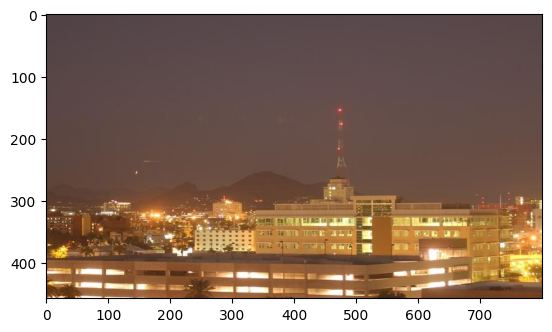

In [44]:
random_img_viz(train_img)

Langkah 3 - Pra Pengolahan Data

In [45]:
	def standarized_input(image):
	    # resize to w: 1100, h:600
	    std_img = cv2.resize(image, (1100,600))

	    return std_img

Selanjutnya, buatlah fungsi untuk kebutuhan encoding label.

In [46]:
	def label_encoder(label):
	    # Encode the label
	    # day as 1; night as 0
	    num_val = 0

	    if(label == 'day'):
	        num_val = 1

	    return num_val

Terakhir, buatlah fungsi untuk melakukan kedua hal tersebut secara sekaligus untuk semua gambar dalam list.

In [47]:
	def preprocess(img_list):
	    std_img_list = []

	    for item in img_list:
	        image = item[0]
	        label = item[1]

	        # Standarized the image
	        std_img = standarized_input(image)

	        # Create the label
	        img_label = label_encoder(label)

	        std_img_list.append((std_img, img_label))

	    return std_img_list

Lakukan pra pengolahan data pada data training.

In [48]:
train_std_img_list = preprocess(train_img)

Lakukan pengecekan ukuran gambar secara acak.

In [49]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_std_img_list))

	# Check img size
	print(f'Image {pick_random}')
	print(train_std_img_list[pick_random][0].shape)

Image 167
(600, 1100, 3)


Langkah 4 - Ekstraksi Fitur

In [50]:
	# Get feature based on average brightness using HSV colorspace
	def avg_brightness(image):
	    # Convert image to HSV
	    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

	    # Calculate the avg of brightness
	    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
	    area = image.shape[0] * image.shape[1]
	    avg = sum_brightness / area

	    return avg

Lakukan pengecekan pada gambar secara acak. INGAT! Gunakan gambar yang telah melalui proses pra pengolahan data!

Image 166
Avg Brighness: 110.1306


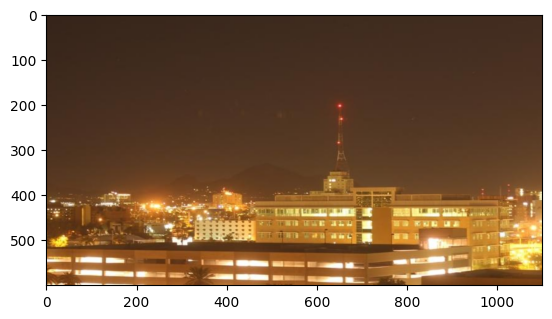

In [51]:
	# Check on random image
	rand_img = np.random.randint(0, len(train_std_img_list))

	feature_img = train_std_img_list[rand_img][0]

	avg_img = avg_brightness(feature_img)

	print(f'Image {rand_img}')
	print(f'Avg Brighness: {avg_img:.4f}')
	plt.imshow(feature_img)

Langkah 5 - Klasifikasi dengan Metode Threshold

In [52]:
	def predict_label(img, threshold):
	    # Computer average brightness
	    avg = avg_brightness(img)
	    pred = 0

	    # Predict the label based on user defined threshold
	    if avg > threshold:
	        pred = 1

	    return pred

Lakukan pengecekan prediksi secara acak pada data training

Image 46
Actual label: 1
Predicted label: 1


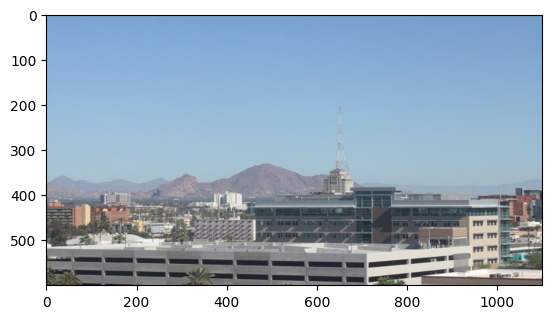

In [53]:
	# Test the classifier on train data
	rand_img = np.random.randint(0, len(train_std_img_list))

	pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

	# Evaluate
	print(f'Image {rand_img}')
	print(f'Actual label: {train_std_img_list[rand_img][1]}')
	print(f'Predicted label: {pred}')
	plt.imshow(train_std_img_list[rand_img][0])

Langkah 6 - Evaluasi Manual

In [54]:
	def evaluate(img_list, threshold):
	    miss_labels = []

	    for file in img_list:
	        # Get the ground truth / correct label
	        img = file[0]
	        label = file[1]

	        # Get prediction
	        pred_label = predict_label(img, threshold)

	        # Compare ground truth and pred
	        if pred_label != label:
	            miss_labels.append((img, pred_label, label))

	    total_img = len(img_list)
	    corr_pred = total_img - len(miss_labels)
	    accuracy = corr_pred / total_img

	    print(f'Accuracy: {accuracy:.4f}')

Lakukan evaluasi pada data training dengan nilai ambang batas 120.

In [55]:
	# Evaluate on train data
	evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


Selanjutnya, kita akan melakukan evaluasi pada data testing. Namun sebelumnya, data testing harus diperlakukan sama dengan data training dalam konteks pra progolahan data dan ekstraksi fitur.

In [56]:
	# Evaluate on test data

	# Load test data
	test_img = load_dataset(test_dir)

	# Preprocess
	test_std_img_list = preprocess(test_img)

	# Predict
	evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


Langkah 4 Alternatif - Membuat Feature Vectors.

In [57]:
	# Create function to extract feature for every images and stored in tabular data
	# Stored in Pandas dataframe
	def extract_avg_bright_feature(img_list):
	    avg_list = []
	    labels = []

	    for img in img_list:
	        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
	        img_label = img[1] # Get the image label

	        avg_list.append(img_avg)
	        labels.append(img_label)

	    # Stack data in columcular way
	    data = np.column_stack((avg_list, labels))
	    # Create a Pandas dataframe
	    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

	    return df

Cek hasilnya pada data training

In [59]:
	# Extract feature on train data
	train_avg_img = extract_avg_bright_feature(train_std_img_list)
	print(f'Shape: {train_avg_img.shape}')
	train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,110.299155,1.0
1,105.506424,1.0
2,131.771191,1.0
3,116.668502,1.0
4,109.947203,1.0


Lakukan langkah yang serupa pada data testing

In [60]:
	# Do the same thing on test data
	test_avg_img = extract_avg_bright_feature(test_std_img_list)
	print(f'Shape: {test_avg_img.shape}')
	test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,150.341579,1.0
1,116.048989,1.0
2,153.885708,1.0
3,140.594911,1.0
4,99.537641,1.0


Langkah 5 - Buat Model SVM

In [61]:
	# import requied library
	from sklearn.svm import SVC

	# Split data and label
	X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
	y_train = train_avg_img.iloc[:,1]
	X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
	y_test = test_avg_img.iloc[:,1]

	model = SVC()
	model.fit(X_train, y_train)

SVC()

Langkah 6 - Evaluasi

Selanjutnya, kita akan melakukan evaluasi pada data training dan testing dengan bantuan library scikit-learn.

In [62]:
	from sklearn.metrics import accuracy_score

	# Make a prediction on train data
	y_train_pred = model.predict(X_train)

	# Get the accuracy on train data
	acc_train = accuracy_score(y_train, y_train_pred)

	# Make a prediction on test data
	y_test_pred = model.predict(X_test)

	# Get the accuracy on test data
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print Eval Result
	print(f'Accuracy on train: {acc_train}')
	print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


## Tugas Praktikum

1. Buatlah model SVM dengan menggunakan data voice.csv dengan ketentuan,

*   Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.
     ▶ Gunakan model dengan kernel linier.
     ▶ Gunakan model dengan kernel polynomial.

     ▶ Gunakan model dengan kernel RBF.

*   Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.

Import library

In [63]:
# Import library
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

Membaca dataset

In [65]:
# Membaca dataset voice.csv
df = pd.read_csv('/content/voice.csv')

# Menampilkan 5 data pertama
display(df.head())

# Menampilkan informasi dataset
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

# Menghitung jumlah setiap kelas
print("\nJumlah data berdasarkan label:")
print(df['label'].value_counts())

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Ukuran dataset: (3168, 21)

Nama kolom:
['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']

Jumlah data berdasarkan label:
label
male      1584
female    1584
Name: count, dtype: int64


Memisahkan fitur dan label

In [66]:
# Memisahkan fitur dan target
X = df.drop(columns=['label'])
y = df['label']

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("Kelas target:", y.unique())

Jumlah fitur: 20
Jumlah data: 3168
Kelas target: ['male' 'female']


Membuat enam model SVM

In [67]:
# Menyimpan hasil pengujian
hasil = []

# Jenis kernel yang digunakan
kernel_list = ['linear', 'poly', 'rbf']

# Rasio data uji: 30% dan 20%
rasio_test = [0.3, 0.2]

for test_size in rasio_test:

    # Membagi data latih dan data uji
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    for kernel in kernel_list:

        # Membuat model SVM
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel=kernel)
        )

        # Melatih model
        model.fit(X_train, y_train)

        # Melakukan prediksi
        y_pred = model.predict(X_test)

        # Menghitung akurasi
        akurasi = accuracy_score(y_test, y_pred)

        # Menyimpan hasil
        hasil.append({
            'Rasio Split': (
                f'{int((1-test_size)*100)}:'
                f'{int(test_size*100)}'
            ),
            'Kernel': kernel,
            'Akurasi (%)': round(akurasi * 100, 2)
        })

        print(
            f"Split {int((1-test_size)*100)}:"
            f"{int(test_size*100)}"
            f" | Kernel: {kernel}"
            f" | Akurasi: {akurasi*100:.2f}%"
        )

Split 70:30 | Kernel: linear | Akurasi: 97.90%
Split 70:30 | Kernel: poly | Akurasi: 96.00%
Split 70:30 | Kernel: rbf | Akurasi: 98.32%
Split 80:20 | Kernel: linear | Akurasi: 97.48%
Split 80:20 | Kernel: poly | Akurasi: 95.58%
Split 80:20 | Kernel: rbf | Akurasi: 98.26%


Membuat tabel performansi akurasi

In [70]:
tabel_hasil = pd.DataFrame(hasil)
tabel_hasil = tabel_hasil[['Rasio Split', 'Kernel', 'Akurasi (%)']]

display(tabel_hasil)

,Rasio Split,Kernel,Akurasi (%)
0,70:30,linear,97.90
1,70:30,poly,96.00
2,70:30,rbf,98.32
3,80:20,linear,97.48
4,80:20,poly,95.58
5,80:20,rbf,98.26


Menentukan model dengan akurasi tertinggi

In [69]:
# Mencari model dengan akurasi tertinggi
indeks_terbaik = tabel_hasil['Akurasi (%)'].idxmax()
model_terbaik = tabel_hasil.loc[indeks_terbaik]

print("Model dengan akurasi tertinggi:")
display(model_terbaik)

Model dengan akurasi tertinggi:


,2
Rasio Split,70:30
Kernel,rbf
Akurasi (%),98.32


Berdasarkan hasil pengujian, model SVM dengan kernel RBF memperoleh akurasi tertinggi pada kedua rasio pembagian data, yaitu 98,32% pada rasio 70:30 dan 98,26% pada rasio 80:20. Kernel polynomial memperoleh akurasi terendah pada kedua rasio tersebut. Jadi, kernel RBF dengan rasio split 70:30 menjadi model terbaik berdasarkan nilai akurasi, yaitu sebesar 98,32%.

2. Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histrogram. Gunakan rasio 80:20. Anda dapat bereksperimen dengan hyperparameter tunning dari kernel RBF. Catat performansi akurasinya!

Membaca dataset praktikum 5

In [72]:
import os

for root, dirs, files in os.walk('/content'):
    gambar = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
    ]

    if gambar:
        print(f"\nFolder: {root}")
        print(f"Jumlah gambar: {len(gambar)}")


Folder: /content/images/training/day
Jumlah gambar: 120

Folder: /content/images/training/night
Jumlah gambar: 120

Folder: /content/images/test/day
Jumlah gambar: 80

Folder: /content/images/test/night
Jumlah gambar: 80

Folder: /content/__MACOSX/images/training/day
Jumlah gambar: 120

Folder: /content/__MACOSX/images/training/night
Jumlah gambar: 120

Folder: /content/__MACOSX/images/test/day
Jumlah gambar: 80

Folder: /content/__MACOSX/images/test/night
Jumlah gambar: 80


Ekstraksi fitur histogram

In [73]:

import os
import cv2
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Lokasi dataset
dataset_dir = '/content/images'

# Menyimpan fitur histogram dan label
fitur = []
label = []

# Membaca gambar dari folder day dan night
for kelas in ['day', 'night']:
    folder = os.path.join(dataset_dir, 'training', kelas)

    for nama_file in os.listdir(folder):
        path = os.path.join(folder, nama_file)

        gambar = cv2.imread(path)

        if gambar is None:
            continue

        # Mengubah gambar menjadi HSV
        hsv = cv2.cvtColor(gambar, cv2.COLOR_BGR2HSV)

        # Ekstraksi histogram warna
        hist = cv2.calcHist(
            [hsv], [0, 1, 2], None,
            [8, 8, 8], [0, 180, 0, 256, 0, 256]
        )

        # Normalisasi histogram
        hist = cv2.normalize(hist, hist).flatten()

        fitur.append(hist)
        label.append(kelas)

X = np.array(fitur)
y = np.array(label)

print("Jumlah gambar:", len(X))
print("Jumlah fitur histogram:", X.shape[1])
print("Jumlah kelas:", len(np.unique(y)))
print("Distribusi label:")
print(pd.Series(y).value_counts())


Jumlah gambar: 240
Jumlah fitur histogram: 512
Jumlah kelas: 2
Distribusi label:
day      120
night    120
Name: count, dtype: int64


Membagi data 80:20

In [74]:
# Membagi data menjadi 80% data latih dan 20% data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))
print("Rasio split: 80:20")


Jumlah data latih: 192
Jumlah data uji: 48
Rasio split: 80:20


Melatih SVM dengan kernel RBF

coba beberapa kombinasi nilai hyperparameter C dan gamma. Nilai C mengatur penalti terhadap kesalahan klasifikasi, sedangkan gamma mengatur jangkauan pengaruh setiap data pada kernel RBF.

In [75]:

from sklearn.model_selection import ParameterGrid

# Kombinasi hyperparameter yang akan diuji
parameter_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

hasil = []

for parameter in ParameterGrid(parameter_grid):
    model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel='rbf',
            C=parameter['C'],
            gamma=parameter['gamma']
        )
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    akurasi = accuracy_score(y_test, y_pred)

    hasil.append({
        'Kernel': 'RBF',
        'C': parameter['C'],
        'Gamma': parameter['gamma'],
        'Akurasi (%)': round(akurasi * 100, 2)
    })

# Menampilkan hasil seluruh percobaan
tabel_hasil = pd.DataFrame(hasil)
tabel_hasil = tabel_hasil.sort_values(
    by='Akurasi (%)',
    ascending=False
).reset_index(drop=True)

display(tabel_hasil)


,Kernel,C,Gamma,Akurasi (%)
0,RBF,1.0,0.01,100.00
1,RBF,1.0,scale,100.00
2,RBF,10.0,0.01,100.00
3,RBF,10.0,scale,100.00
4,RBF,100.0,scale,100.00
5,RBF,100.0,0.01,100.00
6,RBF,0.1,scale,91.67
7,RBF,100.0,0.1,75.00
8,RBF,10.0,0.1,75.00
9,RBF,1.0,0.1,72.92


Menentukan model terbaik

In [76]:

# Mengambil kombinasi dengan akurasi tertinggi
hasil_terbaik = tabel_hasil.iloc[0]

print("Hasil hyperparameter terbaik:")
print("Kernel       : RBF")
print("C            :", hasil_terbaik['C'])
print("Gamma        :", hasil_terbaik['Gamma'])
print("Akurasi      :", hasil_terbaik['Akurasi (%)'], "%")


Hasil hyperparameter terbaik:
Kernel       : RBF
C            : 1.0
Gamma        : 0.01
Akurasi      : 100.0 %


Berdasarkan pengujian klasifikasi gambar siang dan malam menggunakan algoritma Support Vector Machine (SVM) dengan kernel RBF, ekstraksi fitur dilakukan menggunakan histogram warna HSV yang menghasilkan 512 fitur pada setiap gambar. Dataset terdiri dari 240 gambar, yaitu 120 gambar siang dan 120 gambar malam, kemudian dibagi dengan rasio 80:20 menjadi 192 data latih dan 48 data uji.

Pengujian dilakukan dengan mencoba beberapa kombinasi nilai hyperparameter C dan gamma. Hasilnya menunjukkan bahwa enam kombinasi memperoleh akurasi tertinggi sebesar 100%. Salah satu kombinasi tersebut adalah C = 1 dan gamma = 0,01. Jadi, model berhasil mengklasifikasikan seluruh gambar pada data uji dengan benar dalam pengujian ini.